# Regresiones a respuesta Discreta

In [1]:
suppressMessages(library(ggplot2))

#función sigmoide
eta = seq(-10,10,by=0.01)
sigma <- function(x){return( exp(x)/(exp(x)+1))}

    TrLevel         SAT       
 Min.   :0.0   Min.   :463.0  
 1st Qu.:0.0   1st Qu.:543.5  
 Median :1.0   Median :567.5  
 Mean   :0.7   Mean   :559.5  
 3rd Qu.:1.0   3rd Qu.:582.0  
 Max.   :1.0   Max.   :649.0  

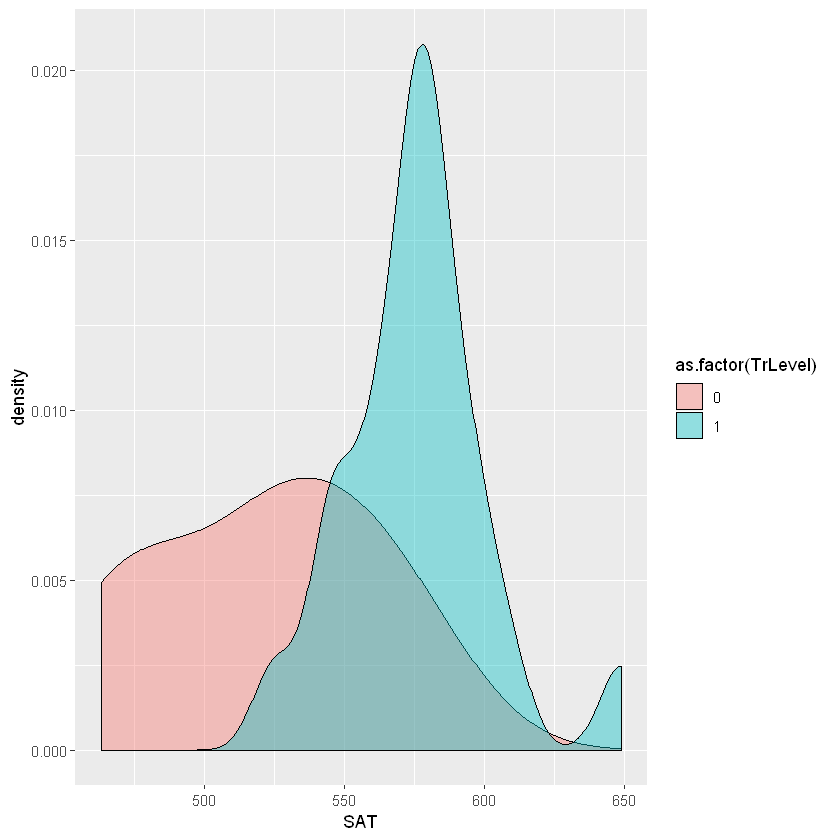

In [2]:
#Ejemplo de regresión logística para datos SAT
datos <- read.csv("data/datosSAT.csv",header=TRUE,sep=";")
summary(datos)
#TrLevel es el nivel alcanzado: 1 si pasó el curso 0 si no
#SAT es el puntaje obtenido en el test de Lenguaje
ggplot(datos, aes(SAT, fill = as.factor(TrLevel))) +
  geom_density(alpha = .4)

In [3]:
#estimación regresion logística
res<- glm(TrLevel ~ SAT, data=datos,family = binomial(link = "logit"))
summary(res)


Call:
glm(formula = TrLevel ~ SAT, family = binomial(link = "logit"), 
    data = datos)

Deviance Residuals: 
    Min       1Q   Median       3Q      Max  
-2.2918  -0.1830   0.3662   0.5057   1.5301  

Coefficients:
             Estimate Std. Error z value Pr(>|z|)  
(Intercept) -31.65827   12.69071  -2.495   0.0126 *
SAT           0.05878    0.02296   2.560   0.0105 *
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 36.652  on 29  degrees of freedom
Residual deviance: 21.993  on 28  degrees of freedom
AIC: 25.993

Number of Fisher Scoring iterations: 5


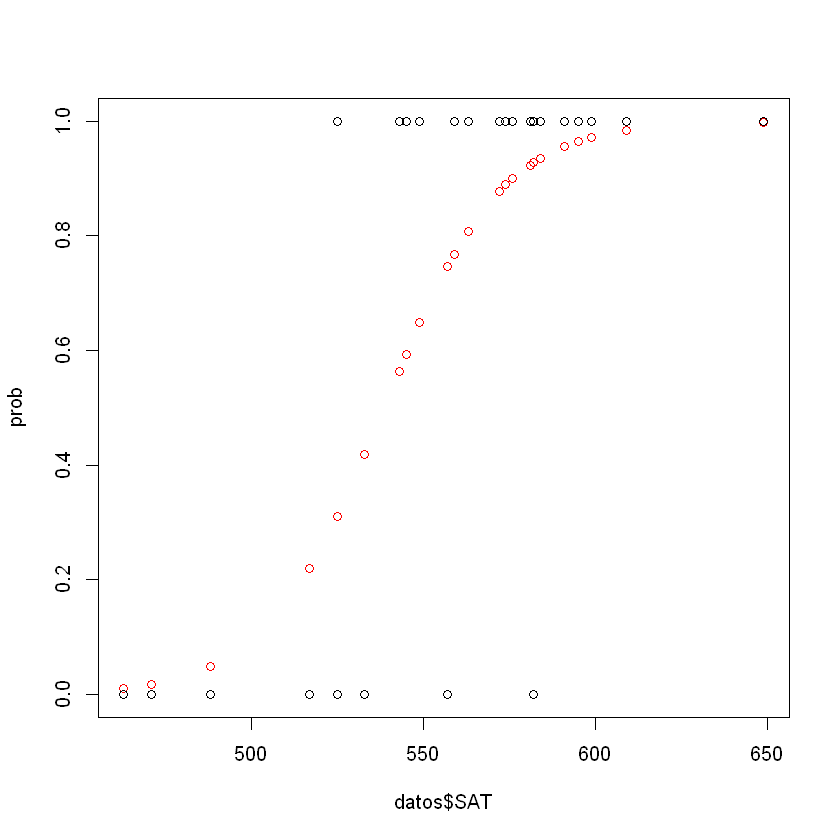

In [4]:
#graficamos los resultados
dat <-cbind(rep(1,30),datos$SAT)
prob <- sigma(dat%*%res$coefficients)
plot(datos$SAT,prob,col="red",ylim=c(0,1))
points(datos$SAT,datos$TrLevel)

**Ejercicio II.1:**

a) Interprete los resultados

b) Indage en la función glm el método de estimación del modelo logit que utiliza y los principales parámetros disponibles.

c) Describa formalmente el método de estimación del modelo logit que usa glm y haga una comparación con los otros métodos disponibles. Para ello use como referencia el Cap. 8 de "Machine Learning, a Probabilistic Perspective", K. Murphy.

In [5]:
#ejemplo de regresión de Poisson que considera datos simulados sobre 200 estudiantes de EM
#la variable a explicar es el número de premios obtenidos y las variables explicativas
#son sus puntajes en el examen final de matemáticas, y el tipo de programa en que 
#están matriculados: general, vocacional o académico.
require(ggplot2)

p <- read.csv("https://stats.idre.ucla.edu/stat/data/poisson_sim.csv")
p <- within(p, {
  prog <- factor(prog, levels=1:3, labels=c("General", "Academic", 
                                                     "Vocational"))
  id <- factor(id)
})
print(p[1:20,])
summary(p)

    id num_awards       prog math
1   45          0 Vocational   41
2  108          0    General   41
3   15          0 Vocational   44
4   67          0 Vocational   42
5  153          0 Vocational   40
6   51          0    General   42
7  164          0 Vocational   46
8  133          0 Vocational   40
9    2          0 Vocational   33
10  53          0 Vocational   46
11   1          0 Vocational   40
12 128          0   Academic   38
13  16          0 Vocational   44
14 106          0 Vocational   37
15  89          0 Vocational   40
16 134          0    General   39
17  19          0    General   43
18 145          0 Vocational   38
19  11          0   Academic   45
20 117          0 Vocational   39


       id        num_awards           prog          math      
 1      :  1   Min.   :0.00   General   : 45   Min.   :33.00  
 2      :  1   1st Qu.:0.00   Academic  :105   1st Qu.:45.00  
 3      :  1   Median :0.00   Vocational: 50   Median :52.00  
 4      :  1   Mean   :0.63                    Mean   :52.65  
 5      :  1   3rd Qu.:1.00                    3rd Qu.:59.00  
 6      :  1   Max.   :6.00                    Max.   :75.00  
 (Other):194                                                  

In [6]:
with(p, tapply(num_awards, prog, function(x) {
  sprintf("M (SD) = %1.2f (%1.2f)", mean(x), sd(x))
}))

General               Academic             Vocational 
"M (SD) = 0.20 (0.40)" "M (SD) = 1.00 (1.28)" "M (SD) = 0.24 (0.52)"

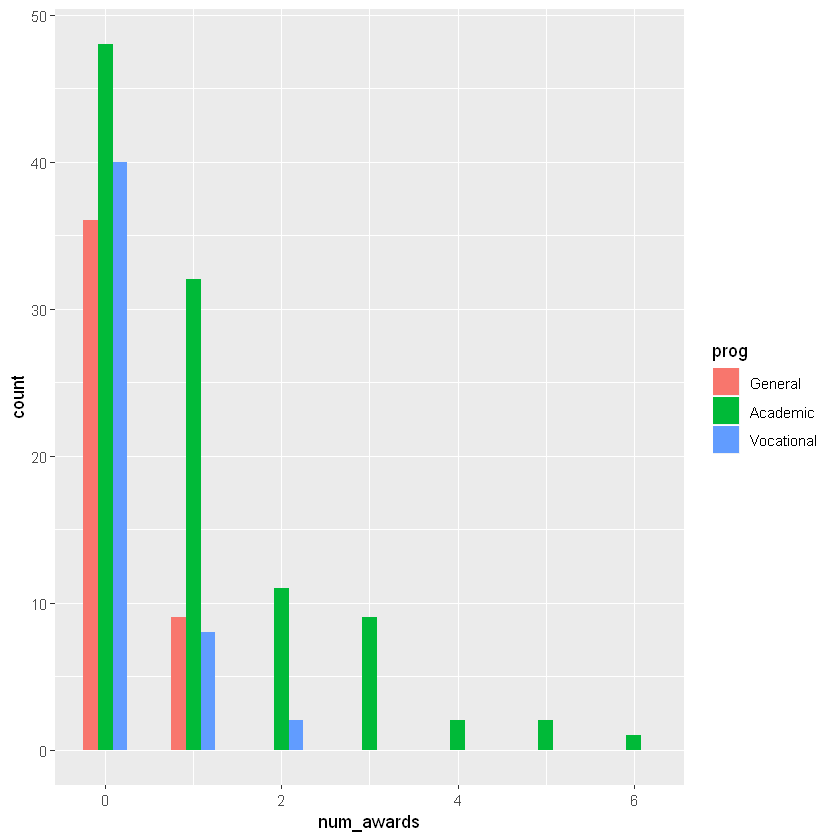

In [7]:
ggplot(p, aes(num_awards, fill = prog)) +
  geom_histogram(binwidth=.5, position="dodge")

In [8]:
summary(m1 <- glm(num_awards ~ prog + math, family="poisson", data=p))


Call:
glm(formula = num_awards ~ prog + math, family = "poisson", data = p)

Deviance Residuals: 
    Min       1Q   Median       3Q      Max  
-2.2043  -0.8436  -0.5106   0.2558   2.6796  

Coefficients:
               Estimate Std. Error z value Pr(>|z|)    
(Intercept)    -5.24712    0.65845  -7.969 1.60e-15 ***
progAcademic    1.08386    0.35825   3.025  0.00248 ** 
progVocational  0.36981    0.44107   0.838  0.40179    
math            0.07015    0.01060   6.619 3.63e-11 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

(Dispersion parameter for poisson family taken to be 1)

    Null deviance: 287.67  on 199  degrees of freedom
Residual deviance: 189.45  on 196  degrees of freedom
AIC: 373.5

Number of Fisher Scoring iterations: 6


In [9]:
with(m1, cbind(res.deviance = deviance, df = df.residual,
  p = pchisq(deviance, df.residual, lower.tail=FALSE)))

res.deviance,df,p
189.4496,196,0.6182274


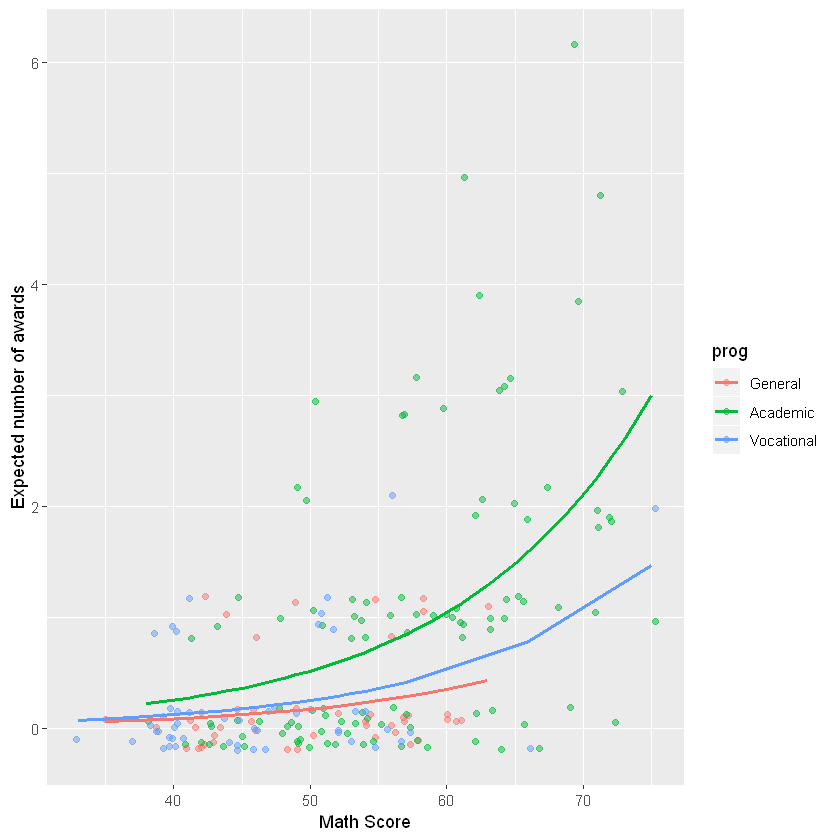

In [10]:
## calculate and store predicted values
p$phat <- predict(m1, type="response")

## order by program and then by math
p <- p[with(p, order(prog, math)), ]

## create the plot
ggplot(p, aes(x = math, y = phat, colour = prog)) +
  geom_point(aes(y = num_awards), alpha=.5, position=position_jitter(h=.2)) +
  geom_line(size = 1) +
  labs(x = "Math Score", y = "Expected number of awards")

**Ejercicio II.2:**

a) Interprete los resultados de este análisis

b) Rehaga sus cálculos considerando una variable explicativa a la vez. Interprete sus resultados

c) Investigue estrategias para comparar los modelos en (a) y (b). Concluya.